# 15 - Capillary Pressure & Saturation-Height

**Part B - Petrophys Curriculum**

Water saturation from resistivity (Archie) tells you the fluid content *at each
depth independently*. A **saturation-height model** does something different and
deeper: it predicts $S_w$ from the **rock quality (porosity, permeability)** and
the **height above the free-water level (FWL)**, grounded in the physics of
**capillary pressure**. It lets you populate $S_w$ where logs are poor, build a
consistent 3-D saturation model, and QC the resistivity-based $S_w$.

This notebook demonstrates the `petrophys.interpretation.saturation.height`
module - capillary-pressure primitives, the Leverett J-function, a fitted
J-function model, and a log-column Sw-vs-depth predictor - using Costa
carbonate core data (well **HW-3**). HW-3 ships no laboratory $P_c$ curve, so
the J-function is fitted the field way, from core rock quality and an assumed
FWL; the library's single-plug lab-curve fitter (`fit_brooks_corey`) is
referenced but not demonstrated - we do not fabricate lab data.

## Learning goals

- Convert between **capillary pressure ($P_c$)** and **height above the FWL**,
  and understand the buoyancy that lifts hydrocarbon into the pore system.
- Normalise Pc across rock qualities with the **Leverett J-function**.
- **Fit** a J-function ($S_w = a\,J^b$) to core data, and know when the
  single-plug Brooks-Corey fitter applies instead.
- Convert a **laboratory** Pc (air-mercury) to **reservoir** conditions.
- Predict **$S_w$ versus depth from logs** with a fitted model + an FWL depth,
  and overlay it on the log-derived $S_w$.

## Why this matters (the physics)

Above the free-water level, buoyancy of the lighter hydrocarbon against the
denser water creates a **capillary pressure** that forces water out of the
larger pores first. In field units:

$$P_c = 0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})\,h \quad [\text{psi}],\; h\text{ in ft}$$

so **height above the FWL is just a rescaled capillary pressure**. At a given
height, a *tight* rock (small pores, high entry pressure) holds **more** water
than a *good* rock. To compare rocks of different quality on one curve, Leverett
defined the dimensionless **J-function**:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\,\sqrt{\frac{k}{\phi}}$$

which folds in each rock's $k/\phi$. Fitting $S_w = a\,J^b$ once then lets us map
**any** ($k,\phi,h$) triple to a saturation - the engine of a saturation-height
model.

### Prerequisites
Work through Part A water-saturation (07) and permeability (08) first. Knowing
Archie $S_w$ and the porosity/permeability curves will make the log overlay at
the end meaningful.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.interpretation.saturation.height import (
    # capillary primitives
    pc_from_height, height_from_pc, convert_pc_lab_to_reservoir,
    leverett_j, pc_from_j, FLUID_SYSTEMS,
    # fitted models
    fit_j_function, saturation_height_from_logs,
)

print('petrophys', petrophys.__version__)
print('fluid systems (IFT dyne/cm, contact angle deg):')
for name, (ift, theta) in FLUID_SYSTEMS.items():
    print('  %-12s IFT=%6.1f  theta=%5.1f' % (name, ift, theta))

petrophys 0.1.0
fluid systems (IFT dyne/cm, contact angle deg):
  air_mercury  IFT= 480.0  theta=140.0
  air_brine    IFT=  72.0  theta=  0.0
  oil_brine    IFT=  30.0  theta= 30.0
  gas_brine    IFT=  50.0  theta=  0.0


## 1. Capillary pressure and height above the FWL

The `pc_from_height` / `height_from_pc` pair converts between the two using the
buoyancy gradient $0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})$. Below we use an oil
column: water SG = 1.0, oil SG = 0.8.

In [2]:
sg_water, sg_oil = 1.0, 0.8
heights = np.array([0, 25, 50, 100, 200, 400])   # ft above FWL
pc = pc_from_height(heights, sg_water=sg_water, sg_hc=sg_oil)

tbl = pd.DataFrame({'height above FWL (ft)': heights, 'Pc (psi)': pc})
print(tbl.to_string(index=False))
print()
# round-trip check
h_back = height_from_pc(pc, sg_water=sg_water, sg_hc=sg_oil)
print('round-trip height_from_pc matches:', np.allclose(h_back, heights))
grad = 0.433 * (sg_water - sg_oil)
print('buoyancy gradient = %.4f psi/ft' % grad)

 height above FWL (ft)  Pc (psi)
                     0     0.000
                    25     2.165
                    50     4.330
                   100     8.660
                   200    17.320
                   400    34.640

round-trip height_from_pc matches: True
buoyancy gradient = 0.0866 psi/ft


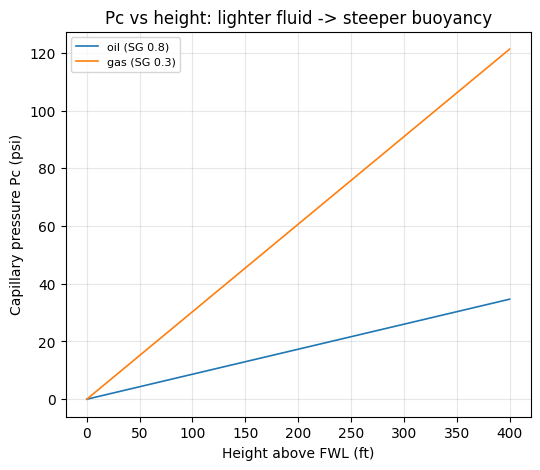

In [3]:
from petrophys.visualization import create_line_comparison

h = np.linspace(0, 400, 100)
series = {
    'oil (SG 0.8)': pc_from_height(h, sg_water, 0.8),
    'gas (SG 0.3)': pc_from_height(h, sg_water, 0.3),
}
# create_line_comparison plots each series vs a shared x; here x is HEIGHT and
# each series is the Pc it produces.
fig, ax = create_line_comparison(
    h, series,
    xlabel='Height above FWL (ft)', ylabel='Capillary pressure Pc (psi)',
    title='Pc vs height: lighter fluid -> steeper buoyancy',
    figsize=(6, 5),
)
plt.show()

Gas (lower SG) has a larger density contrast with water, so it develops the
same capillary pressure over a **shorter** height - gas columns build $P_c$
faster than oil columns.

## 2. Lab-to-reservoir Pc conversion

Core Pc is usually measured in an **air-mercury** or **air-brine** apparatus,
not at reservoir fluid conditions. The measured $P_c$ scales with the
interfacial tension and wettability of the fluid pair:

$$P_{c,res} = P_{c,lab}\,\frac{(\sigma\cos\theta)_{res}}{(\sigma\cos\theta)_{lab}}$$

`convert_pc_lab_to_reservoir` and the `FLUID_SYSTEMS` table make this a one-liner.
Air-mercury Pc is roughly an **order of magnitude** higher than the equivalent
oil-brine reservoir Pc (about 14x with the constants used here).

In [4]:
ift_lab, theta_lab = FLUID_SYSTEMS['air_mercury']   # (480, 140)
ift_res, theta_res = FLUID_SYSTEMS['oil_brine']      # (30, 30)

pc_lab = np.array([50, 100, 200, 500])               # psi, air-mercury
pc_res = convert_pc_lab_to_reservoir(pc_lab, ift_lab, theta_lab, ift_res, theta_res)

conv = pd.DataFrame({'Pc lab air-Hg (psi)': pc_lab, 'Pc res oil-brine (psi)': pc_res})
print(conv.to_string(index=False))
factor = (abs(ift_res * np.cos(np.radians(theta_res)))
          / abs(ift_lab * np.cos(np.radians(theta_lab))))
print('\nconversion factor (res/lab) = %.4f  (~1/%.1f)' % (factor, 1/factor))

 Pc lab air-Hg (psi)  Pc res oil-brine (psi)
                  50                3.532862
                 100                7.065724
                 200               14.131448
                 500               35.328621

conversion factor (res/lab) = 0.0707  (~1/14.2)


## 3. Load the real core well (HW-3)

Costa carbonate well **HW-3** carries core-derived porosity (`PHIE_CC`),
permeability (`PERM_CC`) and an input water saturation (`SW_INPUT`) - the log
$S_w$ we will fit the J-function to and later compare the model back against. Depth is in **feet**.

HW-3 carries no laboratory $P_c$ measurements. For a measured lab drainage
curve the library provides `fit_brooks_corey` (parameters $S_{wir}$, $P_d$,
$\lambda$); with no real lab data bundled we reference it rather than fabricate
a plug, and fit the **J-function** directly on the field data below.

In [5]:
well = read_las(petrophys.sample('HW-3'))
df = well.to_dataframe()
print('well      :', well.name)
print('depth unit:', well.depth_unit)
print('interval  : %.1f - %.1f ft' % (well.start_depth, well.stop_depth))
print('curves    :', well.curves)
for c in ['PHIE_CC', 'PERM_CC', 'SW_INPUT']:
    cc = well.get(c)
    print('  %-9s valid=%3d  range %.3f - %.3f %s'
          % (c, cc.valid_count(), cc.min(), cc.max(), cc.unit))

well      : HW-3
depth unit: ft
interval  : 7805.0 - 8020.0 ft
curves    : ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']
  PHIE_CC   valid=351  range 0.000 - 0.330 ft3/ft3
  PERM_CC   valid=355  range 0.010 - 990.000 mD
  SW_INPUT  valid=321  range 0.040 - 0.940 v/v


### Build a J-function from the core points

We now fit the J-function on the **real HW-3 core**. To turn each core Sw into a
$J$ value we need each point's $P_c$, which we obtain from an **assumed FWL
depth** just below the deepest valid core point (buoyancy converts height above FWL into
$P_c$). This is the standard field workflow when only saturation + rock-quality
core exists and the FWL is picked from pressure data.

In [6]:
depth = df['DEPTH'].values
phi = df['PHIE_CC'].values
perm = df['PERM_CC'].values
sw_log = df['SW_INPUT'].values

# Assumed free-water level a little below the deepest valid core point.
valid = np.isfinite(phi) & np.isfinite(perm) & np.isfinite(sw_log) & (phi > 0) & (perm > 0)
fwl_depth = np.nanmax(depth[valid]) + 20.0     # ft, assumed FWL pick
print('assumed FWL depth = %.1f ft' % fwl_depth)

height = np.clip(fwl_depth - depth, 0.0, None)              # ft above FWL
pc_core = pc_from_height(height, sg_water=1.0, sg_hc=0.8)   # psi
J_core = leverett_j(pc_core, perm, phi,
                    ift=FLUID_SYSTEMS['oil_brine'][0],
                    theta=FLUID_SYSTEMS['oil_brine'][1])

fit_ok = valid & np.isfinite(J_core) & (J_core > 0) & (sw_log > 0) & (sw_log <= 1)
print('points available to fit:', int(fit_ok.sum()))

model = fit_j_function(J_core[fit_ok], sw_log[fit_ok], form='power',
                       ift=FLUID_SYSTEMS['oil_brine'][0],
                       theta=FLUID_SYSTEMS['oil_brine'][1],
                       sg_water=1.0, sg_hc=0.8)
print('HW-3 J-function:  Sw = %.4f * J^(%.4f)   R2 = %.3f'
      % (model.a, model.b, model.r2))

assumed FWL depth = 8010.0 ft
points available to fit: 313
HW-3 J-function:  Sw = 0.0712 * J^(-0.2629)   R2 = 0.192


The $R^2$ is modest - carbonates are heterogeneous and our single assumed
FWL cannot perfectly reconcile every rock type. That is realistic; the model
still captures the first-order trend that better rock (higher $J$) drains to
lower $S_w$.

## 4. Predict Sw vs depth from logs and overlay

`saturation_height_from_logs` takes the fitted J-function, an FWL depth, and the
well's permeability/porosity curves, and returns a **predicted $S_w$ at every
depth**. Height above the FWL is `fwl_depth - depth`; below the FWL height is
clipped to zero -> $S_w = 1$.

One honesty note before reading the error statistic below: `SW_INPUT` is the
**same curve the J-function was fitted to**, so the mean absolute error is an
**in-sample goodness-of-fit check**, not independent prediction skill. Hold out
depths (or a whole well) from the fit for a real validation.

In [7]:
sw_pred = saturation_height_from_logs(
    well, model, fwl_depth=fwl_depth,
    perm_curve=('PERM_CC',), phi_curve=('PHIE_CC',),
    depth_increases_down=True,
)
print('predicted Sw: valid=%d  median=%.3f' % (np.isfinite(sw_pred).sum(),
                                               np.nanmedian(sw_pred)))

both = np.isfinite(sw_pred) & np.isfinite(sw_log)
resid = sw_pred[both] - sw_log[both]
print('vs log Sw: mean abs error = %.3f, bias = %+.3f'
      % (np.nanmean(np.abs(resid)), np.nanmean(resid)))

predicted Sw: valid=324  median=0.090
vs log Sw: mean abs error = 0.028, bias = -0.011


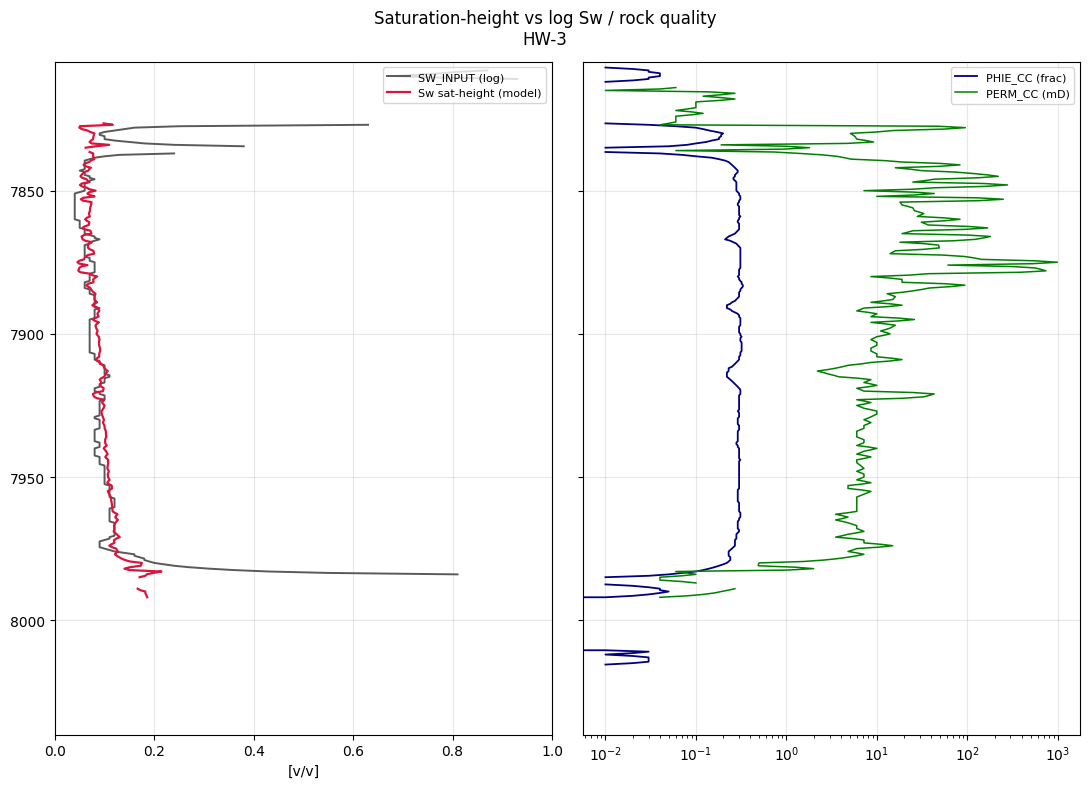

In [8]:
from petrophys.visualization import LogPlot

# Attach the predicted saturation-height Sw so a library plotter can render it.
well.add_curve('SW_SATHEIGHT', sw_pred, unit='v/v', description='Sw from sat-height model')

lp = LogPlot(well, figsize=(11, 8))
lp.create_figure(n_tracks=2)
# Track 0: log Sw vs saturation-height Sw
lp.add_curve(0, 'SW_INPUT', color='0.35', linewidth=1.4, xlim=(0, 1), label='SW_INPUT (log)')
lp.add_curve(0, 'SW_SATHEIGHT', color='crimson', linewidth=1.6, xlim=(0, 1),
             label='Sw sat-height (model)')
# Track 1: rock-quality context (porosity + log permeability)
lp.add_curve(1, 'PHIE_CC', color='navy', linewidth=1.3, label='PHIE_CC (frac)')
lp.add_curve(1, 'PERM_CC', color='green', linewidth=1.1, log_scale=True, label='PERM_CC (mD)')
lp.set_depth_range(top=well.start_depth, bottom=fwl_depth + 30)
lp.add_title('Saturation-height vs log Sw / rock quality')
lp.show()

Where the two $S_w$ curves diverge is diagnostic: if the saturation-height
model reads **drier** than the log $S_w$, either the FWL is picked too deep, the
rock-quality curves are off, or there is a genuine transition-zone /
low-resistivity-pay effect worth investigating.

## 5. The library's saturation-height diagnostic plot

`create_saturation_height_plot` renders the standard two-panel QC: the
**J-function fit** over the core points (left) and the resulting **Sw-vs-height
type curves** for a set of rock classes (right). This is the plot you would put
in a saturation-height report.

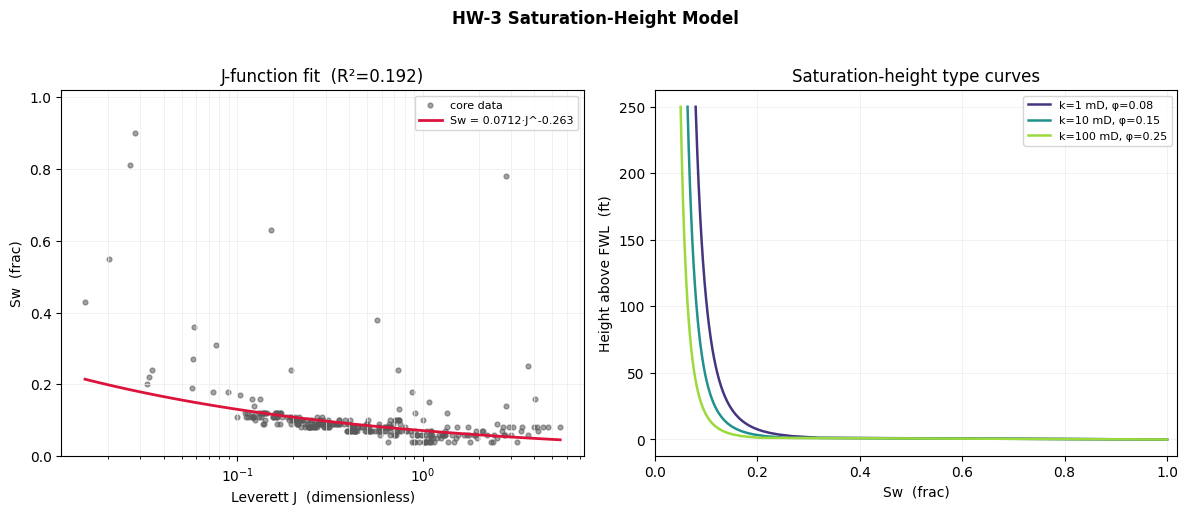

In [9]:
from petrophys.visualization import create_saturation_height_plot

fig = create_saturation_height_plot(
    model,
    j=J_core[fit_ok],
    sw=sw_log[fit_ok],
    rock_classes=[(1.0, 0.08), (10.0, 0.15), (100.0, 0.25)],
    max_height_ft=250.0,
    title='HW-3 Saturation-Height Model',
)
plt.show()

The right-hand type curves show the model's core prediction: at any given
height above the FWL, **better rock (higher $k$, higher $\phi$) holds less
water** - exactly the capillary physics we started with. These curves are what
get handed to the reservoir model to populate $S_w$ away from well control.

## Pitfalls & parameter choices

- **The FWL must come from data.** Here we *assumed* an FWL 20 ft below the
  deepest valid core point to make the demo self-contained; in practice pick it from formation
  pressures (RFT/MDT gradient intersection) or the deepest known water. A wrong
  FWL biases every predicted $S_w$.
- **J-function vs Brooks-Corey.** J-function normalises by $\sqrt{k/\phi}$, so **one**
  fit covers many rock qualities and is the model applied back to logs.
  Brooks-Corey describes a **single** drainage curve - fit it per rock type / per
  plug.
- **Always lab-to-reservoir convert Pc.** Never fit reservoir saturations to raw
  air-mercury Pc; use `convert_pc_lab_to_reservoir` first.
- **Units.** This module is field units throughout: Pc in psi, height in ft, $k$
  in mD, $\phi$ as a **fraction**, IFT in dyne/cm, angle in degrees.
- **Modest $R^2$ is normal** in heterogeneous carbonates; consider fitting
  separate J-functions per flow unit / rock type.

## Recap

- **Height above the FWL is a rescaled capillary pressure**:
  $P_c = 0.433(\mathrm{SG}_w-\mathrm{SG}_{hc})h$.
- The **Leverett J-function** normalises $P_c$ by $\sqrt{k/\phi}$ so different rock
  qualities collapse onto one curve.
- **Brooks-Corey** ($S_{wir}, P_d, \lambda$) describes a single drainage curve;
  the **J power-law** ($S_w = aJ^b$) is what we apply back to logs.
- Lab Pc must be **converted to reservoir** fluid conditions before use.
- `saturation_height_from_logs` turns a fitted model + FWL + $(k,\phi)$ curves
  into a predicted $S_w$ profile you can overlay on the resistivity-based
  $S_w$ (here an in-sample comparison, since the same curve trained the fit).

## Try it yourself

> **Exercise 1.** Move the assumed FWL up and down by +/-30 ft and re-run the
> prediction. How sensitive is the mean absolute error to the FWL pick?
>
> **Exercise 2.** Fit the J-function with `form='power_swir'` and an explicit
> `swir=0.1` floor. Does forcing an irreducible asymptote improve the deep,
> tight-rock predictions?
>
> **Exercise 3.** Using the fitted HW-3 J-function (`model`), compute the height
> above the FWL at which $S_w$ first falls below 0.5 for a 10 mD / 0.15 rock
> versus a 100 mD / 0.25 rock (hint: invert $S_w = a\,J^b$ for $J$, then
> `pc_from_j` and `height_from_pc`).

## What's next

Continue with **16_borehole_image_fmi.ipynb**; then 17 (visualization
masterclass) and 18 (multiwell field study) complete Part B. Along the way,
revisit the Part A
water-saturation notebook (07) and compare its Archie $S_w$ against this
saturation-height prediction - reconciling the two is the heart of a defensible
reservoir saturation model.